# Homework1-Bass Model:Innovation Diffusion Analysis

**Course:** DS 223 Marketing Analytics

**Selected Innovation:** Garmin Index Sleep Monitor

**Historical Look-Alike:** Fitbit Wearable Fitness Trackers

**Geographical Scope:** Worldwide

## 1)Selected Innovation
For this homework, I chose the Garmin Index Sleep Monitor from TIME's Best Inventions of 2025. It is a wearable device designed to monitor sleep and help people better understand their sleep habits. Unlike a regular smartwatch, it is worn on the upper arm during the night. It tracks information such as sleep stages, heart rate variability, and skin temperature, which users can view through the Garmin Connect app.

I chose this product because I find it interesting how technology can help people understand something as important as sleep. Instead of only checking how many steps we take during the day, devices like this allow us to learn more about our health while we are sleeping.

**Product link:** https://time.com/collections/best-inventions-2025/7318552/garmin-index-sleep-monitor/

**Source:** TIME (2025); Garmin (2025).

## 2)Historical Look-Alike Innovation

For the historical comparison, I chose Fitbit fitness trackers. Fitbit became popular because its devices allowed people to monitor their daily activities, such as steps, exercise, and sleep. Garmin Index Sleep Monitor has a similar purpose, as it also uses wearable technology to collect information about people's health. Both products help users understand their habits by collecting data and showing the results through an application. I think Fitbit is a good choice to compare with Garmin it introduced many consumers to the idea of using wearable devices to monitor their health.

However, the two products are not exactly the same. Fitbit trackers are mainly designed for everyday fitness and activity monitoring, although many models also track sleep. On the other hand, Garmin Index Sleep Monitor focuses specifically on sleep and recovery. Another difference is how the devices are worn. Garmin's device is worn on the upper arm, while Fitbit trackers are usually worn on the wrist. Despite these differences, both products belong to the wearable health technology market. For this reason, I will use Fitbit's historical sales data to study how similar technology spread among consumers and to estimate a possible diffusion pattern for Garmin's new product.

**Sources:** Fitbit, Inc. (2015); Garmin (2025).

In [1]:
from pathlib import Path
import os

#The folder where my homework is saved
hw1_folder = Path(r"C:\Users\PC\OneDrive\Desktop\Homeworks\HW1")

os.chdir(hw1_folder)

print("Working folder:", Path.cwd())
print("Dataset found:", Path("data/fitbit_sales_devices_2010_2019.csv").exists())

Working folder: C:\Users\PC\OneDrive\Desktop\Homeworks\HW1
Dataset found: True


In [2]:
import pandas as pd
#Reading the Fitbit sales data
fitbit = pd.read_csv("data/fitbit_sales_devices_2010_2019.csv")

print("Fitbit Worldwide Device Sales(2010-2019)")
display(fitbit[["year", "devices_sold"]])

Fitbit Worldwide Device Sales(2010-2019)


,year,devices_sold
0,2010,58000
1,2011,208000
2,2012,1279000
3,2013,4476000
4,2014,10904000
5,2015,21355000
6,2016,22295000
7,2017,15343000
8,2018,13939000
9,2019,15988000


## 3)Historical Data

For the historical data, I used Fitbit's worldwide device sales from 2010 to 2019. I collected the numbers from Fitbit's official reports published by the U.S. Securities and Exchange Commission(SEC). The 2015 registration statement provides the sales figures for 2010–2014, while the 2019 annual report provides the figures for 2015–2019. I chose these sources because they contain actual sales reported by the company not fake generated numbers.

Looking at the data, Fitbit's sales increased very quickly in the beginning. In 2010, the company sold only 58000 devices, but by 2016, sales had reached 22.295 million. After that, sales started to decrease, although there was a small increase in 2019. This shows that Fitbit experienced strong growth in its early years, but that growth did not continue at the same rate.

One limitation is that the data represents devices sold rather than the exact number of new customers. Some people may have purchased another Fitbit device to replace an older one. For this reason, I will use the sales data as an approximation of adoption when estimating the Bass Model, while keeping this limitation in mind when interpreting the results.

**Data sources:**

1.Fitbit, Inc. (2015). *Registration Statement (Form S-1).* U.S. Securities and Exchange Commission.  
https://www.sec.gov/Archives/edgar/data/1447599/000119312515176980/d875679ds1.htm

2.Fitbit, Inc. (2020). *2019 Annual Report (Form 10-K).* U.S. Securities and Exchange Commission.  
https://www.sec.gov/Archives/edgar/data/1447599/000144759920000016/fit-20191231.htm

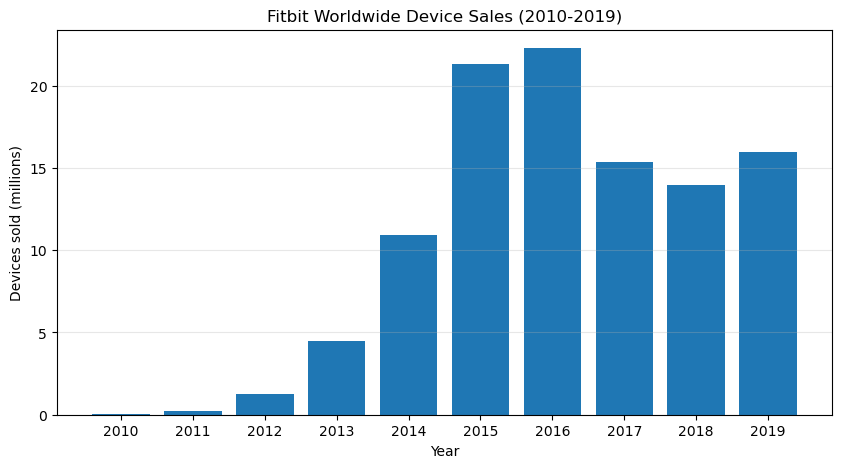

In [3]:
import matplotlib.pyplot as plt
from pathlib import Path

#Fitbit sales in millions
sales_millions = fitbit["devices_sold"] / 1000000

#Plotting the historical sales
plt.figure(figsize=(10, 5))
plt.bar(fitbit["year"], sales_millions)

plt.title("Fitbit Worldwide Device Sales (2010-2019)")
plt.xlabel("Year")
plt.ylabel("Devices sold (millions)")
plt.xticks(fitbit["year"])
plt.grid(axis="y", alpha=0.3)

#Saving the graph for the report
Path("img").mkdir(exist_ok=True)
plt.savefig("img/fitbit_annual_sales.png", dpi=200, bbox_inches="tight")
plt.show()

## Interpretation of Historical Sales

From the graph, we can see that Fitbit's sales grew very quickly between 2010 and 2016. Sales reached their highest point in 2016, at around 22.3 million devices. After 2016, sales decreased, although there was a small increase in 2019. I think this pattern shows how wearable fitness trackers became more popular during Fitbit's early years. However, the decrease in sales after 2016 also shows that growth did not continue forever which could be related to competition, changes in demand, or customers replacing their older devices. The graph alone cannot tell us the exact reasons.

For the Bass Model, I will focus on Fitbit's early growth period and use the later years to see how well the model represents actual sales. Since the data includes device purchases rather than only first-time buyers, the results will be an approximation of adoption.

In [4]:
#Using Fitbit's early growth period
fitbit_growth = fitbit[fitbit["year"] <= 2016].copy()
#Converting sales to millions
fitbit_growth["sales_millions"] = fitbit_growth["devices_sold"] / 1_000_000

#Calculating total sales before each year
fitbit_growth["previous_sales"] = (
    fitbit_growth["sales_millions"].cumsum().shift(fill_value=0)
)

print("Fitbit sales data for Bass Model estimation")
display(fitbit_growth[["year", "sales_millions", "previous_sales"]].round(3))

Fitbit sales data for Bass Model estimation


,year,sales_millions,previous_sales
0,2010,0.058,0.000
1,2011,0.208,0.058
2,2012,1.279,0.266
3,2013,4.476,1.545
4,2014,10.904,6.021
5,2015,21.355,16.925
6,2016,22.295,38.280


In [5]:
import numpy as np
from scipy.optimize import curve_fit

#Bass Model cumulative adoption function F(t)
def bass_F(t, p, q):
    exp_part = np.exp(-(p + q) * t)
    return (1 - exp_part) / (1 + (q / p) * exp_part)

#Bass Model adoption function f(t)
def bass_f(t, p, q):
    exp_part = np.exp(-(p + q) * t)
    return ((p + q)**2 / p) * exp_part / (1 + (q / p) * exp_part)**2

# Predicted sales in millions
def bass_sales(t, p, q, M):
    return M * bass_f(t, p, q)

#Fitbit sales from 2010 to 2016
years = np.arange(1, len(fitbit_growth) + 1)
actual_sales = fitbit_growth["sales_millions"].to_numpy()

# Estimate the parameters using nonlinear least squares
parameters, _ = curve_fit(
    bass_sales,
    years,
    actual_sales,
    p0=[0.02, 0.4, actual_sales.sum()],
    bounds=([1e-8, 1e-8, actual_sales.sum()], [1, 5, 1000]),
    maxfev=50000
)

p, q, M = parameters

print("Estimated Bass Model Parameters")
print(f"p = {p:.6f}")
print(f"q = {q:.6f}")
print(f"M = {M:.3f} million devices")

Estimated Bass Model Parameters
p = 0.000498
q = 1.182733
M = 80.397 million devices


Actual vs Predicted Fitbit Sales(millions)


,Year,Actual sales,Predicted sales
0,2010,0.058,0.130
1,2011,0.208,0.423
2,2012,1.279,1.353
3,2013,4.476,4.143
4,2014,10.904,11.112
5,2015,21.355,21.280
6,2016,22.295,22.316
7,2017,15.343,12.497
8,2018,13.939,4.809
9,2019,15.988,1.589


Training RMSE (2010-2016): 0.176 million
Test RMSE (2017-2019): 9.980 million


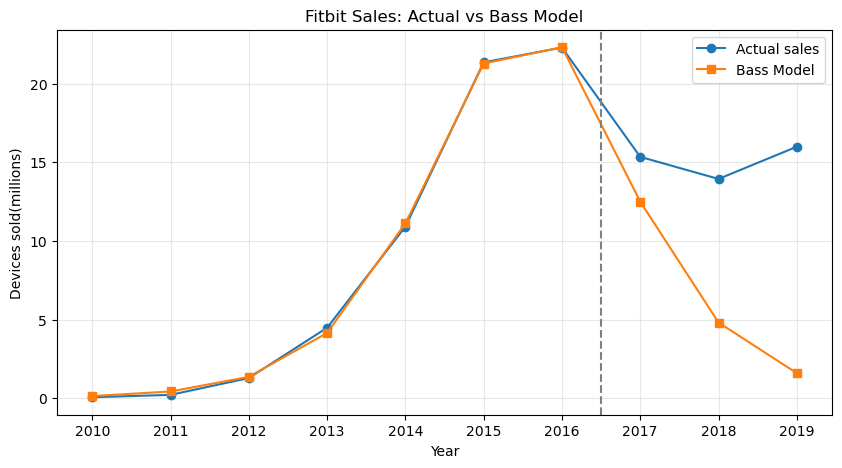

In [6]:
#Comparing actual Fitbit sales with the Bass Model
all_years = np.arange(1, len(fitbit) + 1)

actual = fitbit["devices_sold"].to_numpy() / 1_000_000
predicted = bass_sales(all_years, p, q, M)

#Actual and predicted sales
comparison = pd.DataFrame({
    "Year": fitbit["year"],
    "Actual sales": actual,
    "Predicted sales": predicted
})

print("Actual vs Predicted Fitbit Sales(millions)")
display(comparison.round(3))

#Checking the average prediction errors
train_rmse = np.sqrt(np.mean((actual[:7] - predicted[:7]) ** 2))
test_rmse = np.sqrt(np.mean((actual[7:] - predicted[7:]) ** 2))

print(f"Training RMSE (2010-2016): {train_rmse:.3f} million")
print(f"Test RMSE (2017-2019): {test_rmse:.3f} million")

#Plotting actual and predicted sales
plt.figure(figsize=(10, 5))

plt.plot(fitbit["year"], actual, marker="o", label="Actual sales")
plt.plot(fitbit["year"], predicted, marker="s", label="Bass Model")

plt.axvline(2016.5, linestyle="--", color="gray")
plt.title("Fitbit Sales: Actual vs Bass Model")
plt.xlabel("Year")
plt.ylabel("Devices sold(millions)")
plt.xticks(fitbit["year"])
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("img/fitbit_bass_model_check.png", dpi=200, bbox_inches="tight")
plt.show()

## 4)Bass Model Parameter Estimation

To estimate the Bass Model parameters, I used the Nonlinear Least Squares method like in our lectures. The model has three main parameters: p, q, and M.

p-is the coefficient of innovation. It represents adoption influenced by external factors, such as advertising.
q-is the coefficient of imitation. It represents the influence of people who have already adopted the product.
M-is the market potential, which represents the total potential adoption under the model.

The Bass Model adoption function is:
$$
f(t)=\frac{(p+q)^2e^{-(p+q)t}}{p(1+\frac{q}{p}e^{-(p+q)t})^2}
$$

To estimate the parameters, I used Fitbit's sales data from 2010 to 2016. I chose this period because Fitbit was experiencing rapid growth during these years. I used Python's curve_fit() function, which estimates the parameters by minimizing the squared differences between actual and predicted sales.

The estimated parameters are:
p = 0.000498
q = 1.182733
M = 80.397 million devices

We can see that the value of q is much higher than p, which suggests that imitation plays a larger role than innovation in the fitted diffusion pattern. So the model suggests that adoption increased more strongly as the product became established in the market. However, these coefficients describe the fitted mathematical model, not directly measured customer motivations.

I also compared the model predictions with actual Fitbit sales. For 2010–2016, the RMSE was 0.176 million devices, showing that the model fits the early data quite closely. However, for 2017–2019, the RMSE was much higher at 9.980 million devices. The model predicted that sales would decrease much faster than they actually did.

This difference is important because Fitbit's sales include replacement purchases and may also be affected by competition and changes in consumer demand. The basic Bass Model does not account for all these factors. Therefore, I will use the estimated parameters as a starting point for the Garmin forecast, but the predictions should be understood as approximate rather than exact.

Another limitation is that M is estimated in device units, not unique customers. It also describes the historical Fitbit pattern and cannot be used directly as Garmin's market potential.

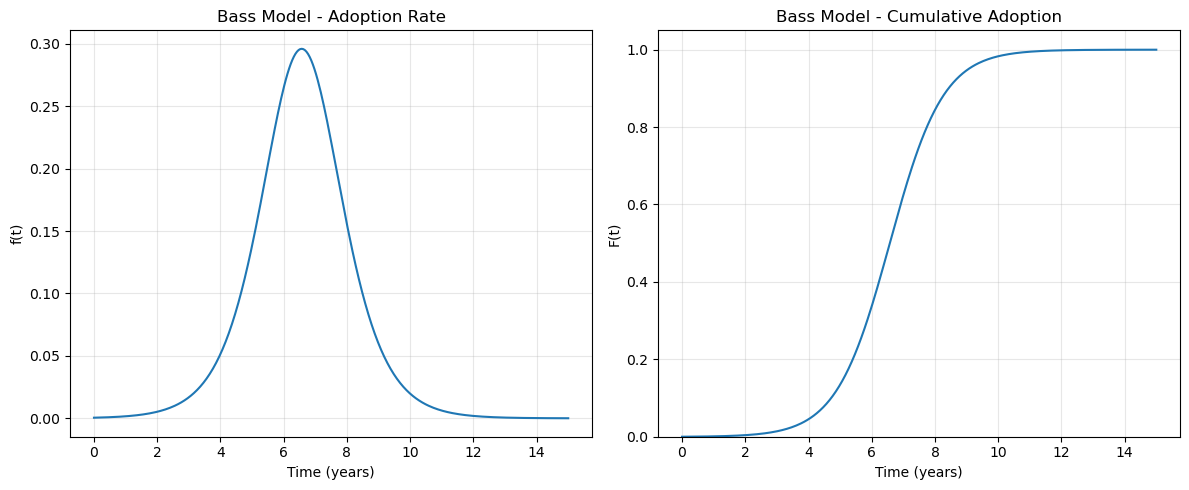

In [7]:
#Plotting the Bass Model adoption rate and cumulative adoption
t = np.linspace(0, 15, 300)

#Using the parameters estimated from Fitbit sales
adoption_rate = bass_f(t, p, q)
cumulative_adoption = bass_F(t, p, q)

plt.figure(figsize=(12, 5))

#Adoption rate f(t)
plt.subplot(1, 2, 1)
plt.plot(t, adoption_rate)
plt.title("Bass Model - Adoption Rate")
plt.xlabel("Time (years)")
plt.ylabel("f(t)")
plt.grid(alpha=0.3)

#Cumulative adoption F(t)
plt.subplot(1, 2, 2)
plt.plot(t, cumulative_adoption)
plt.title("Bass Model - Cumulative Adoption")
plt.xlabel("Time (years)")
plt.ylabel("F(t)")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("img/fitbit_diffusion_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
#Calculating the predicted peak time of adoption
peak_time = np.log(q / p) / (p + q)
print(f"Predicted peak time:{peak_time:.3f} years")

#Comparing with the actual peak year in the historical Fitbit sales
actual_peak_index = fitbit_growth["sales_millions"].idxmax()
actual_peak_year = fitbit_growth.loc[actual_peak_index, "year"]
print(f"Actual peak year in the fitting data:{actual_peak_year}")

Predicted peak time:6.570 years
Actual peak year in the fitting data:2016


## Interpretation of the Bass Model Curves and Peak Time

The first graph shows how the adoption rate changes over time. We can see that at the beginning, adoption is low, but it increases as more people start using the product. After reaching its highest point, the adoption rate decreases. The second graph shows cumulative adoption, which follows an S-shaped curve and gradually approaches the estimated market potential. Using the formula from our lecture, I calculated that the predicted peak occurs at approximately 6.570 years. Since 2010 is the first year in my dataset, this places the peak between 2015 and 2016. Looking at the actual sales data, Fitbit reached its highest annual sales in 2016, with 22.295 million devices sold. This means the model's predicted peak is close to the actual peak.
However, the model fits the early growth period much better than the later years. I think this is important because it shows that the Bass Model can help explain how an innovation spreads, but it cannot capture every factor affecting sales. Also, Fitbit's sales include replacement purchases, so the estimated diffusion pattern is only an approximation of new customer adoption.

## 5)Geographical Scope

For this analysis, I chose to focus on the worldwide market rather than a single country. The main reason is that my historical Fitbit dataset includes worldwide sales, so using the same geographical scope for Garmin makes the comparison more consistent. Another reason is that Garmin sells its products internationally. According to Garmin's 2024 annual report, the company reported approximately USD 3.04 billion in sales in the Americas, USD 2.32 billion in Europe, the Middle East and Africa, and USD 0.94 billion in Asia-Pacific.These figures are for all Garmin products, not only the Index Sleep Monitor. The Index Sleep Monitor was also announced in different markets, including the United States and Singapore, in 2025.
In my opinion the worldwide market is more suitable because Garmin can reach customers in different countries. However, this does not mean that everyone who uses a Garmin device will buy the Index Sleep Monitor. It is a more specialized product, so I will estimate a separate market potential for it instead of using Fitbit's market potential directly.

Sources:

1.Garmin Ltd. (2025). *2024 Annual Report (Form 10-K).* U.S. Securities and Exchange Commission.  
https://www.sec.gov/Archives/edgar/data/1121788/000095017025022760/grmn-20241228.htm

2.Garmin (2025). *Rest easy with the Index Sleep Monitor smart sleep band from Garmin.*  
https://www.garmin.com/en-US/newsroom/press-release/wearables-health/rest-easy-with-the-index-sleep-monitor-smart-sleep-band-from-garmin/

3.Garmin Singapore (2025). *Rest easy with the Index Sleep Monitor smart sleep band from Garmin.*  
https://www.garmin.com.sg/news/press-release/news-2025-jul-index-sleep-monitor/

In [9]:
#Estimating Garmin's market potential using Fermi logic

#Garmin sold about 18.6 million units in 2024
garmin_units_2024 = 18_600_000

#Different assumptions for the sleep monitor
market_shares = [0.01, 0.02, 0.05]
scenario_names = ["Low", "Base", "High"]

#Calculating the potential market for each scenario
market_scenarios = pd.DataFrame({
    "Scenario": scenario_names,
    "Assumed share": market_shares
})

market_scenarios["Market potential"] = (
    garmin_units_2024 * market_scenarios["Assumed share"]
).astype(int)

#Using the base scenario for the main forecast
garmin_M = 372_000

print("Estimated Garmin Index Sleep Monitor Market Potential")
display(market_scenarios)

print(f"Base market potential: {garmin_M:,} devices")

#Saving results
market_scenarios.to_csv("data/garmin_market_scenarios.csv", index=False)

Estimated Garmin Index Sleep Monitor Market Potential


,Scenario,Assumed share,Market potential
0,Low,0.01,186000
1,Base,0.02,372000
2,High,0.05,930000


Base market potential: 372,000 devices


## 6)Estimating Garmin's Market Potential

Before predicting Garmin Index Sleep Monitor adoption, I need to estimate its market potential. I cannot use Fitbit's estimated 80.397 million devices directly because Garmin's sleep monitor is a more specialized product.
According to Garmin's 2024 annual report, the company sold approximately 18.6 million devices worldwide in 2024 which includes all Garmin product categories, not only health and fitness devices. I used this figure as a general benchmark for the company's size.
Since I could not find a published estimate of how many people might eventually buy the Index Sleep Monitor, I used Fermi logic. I considered three possible scenarios: 1%, 2%, and 5% of Garmin's 2024 annual device sales. These percentages are my assumptions, not actual customer survey results or estimates published by Garmin. I chose relatively small percentages because the Index Sleep Monitor is designed for a narrower group of customers interested in sleep tracking.
Based on these assumptions, I estimated a market potential of 186,000 devices in the low scenario, 372,000 in the base scenario, and 930,000 in the high scenario. I will use 372,000 as the main market potential for the Bass Model forecast.
However, this calculation has an important limitation. Garmin's annual device sales are not the same as its number of unique customers or the total number of people who might buy a sleep monitor over several years. Therefore, these numbers should be treated as illustrative market-size scenarios, not reliable estimates of actual future demand. Comparing all three scenarios will help show how much the forecast depends on my assumptions.

Source:

Garmin Ltd. (2025). *2024 Annual Report (Form 10-K).* U.S. Securities and Exchange Commission.
https://www.sec.gov/Archives/edgar/data/1121788/000095017025022760/grmn-20241228.htm

In [10]:
#Predicting Garmin Index Sleep Monitor adoption

#Forecasting the first 15 years after launch
t_forecast = np.arange(1, 16)
forecast_years = np.arange(2025, 2040)

#Using the Fitbit p and q values and Garmin's estimated market size
garmin_new = garmin_M * (
    bass_F(t_forecast, p, q) - bass_F(t_forecast - 1, p, q)
)

garmin_total = garmin_M * bass_F(t_forecast, p, q)

#prediction table
garmin_forecast = pd.DataFrame({
    "Year": forecast_years,
    "Period": t_forecast,
    "New adopters": np.rint(garmin_new).astype(int),
    "Cumulative adopters": np.rint(garmin_total).astype(int)
})

print("Garmin Index Sleep Monitor-Bass Model Forecast")
display(garmin_forecast)
garmin_forecast.to_csv("data/garmin_forecast.csv", index=False)

Garmin Index Sleep Monitor-Bass Model Forecast


,Year,Period,New adopters,Cumulative adopters
0,2025,1,354,354
1,2026,2,1151,1505
2,2027,3,3708,5213
3,2028,4,11607,16820
4,2029,5,33260,50080
5,2030,6,75377,125457
6,2031,7,106817,232274
7,2032,8,81858,314131
8,2033,9,38001,352132
9,2034,10,13548,365681


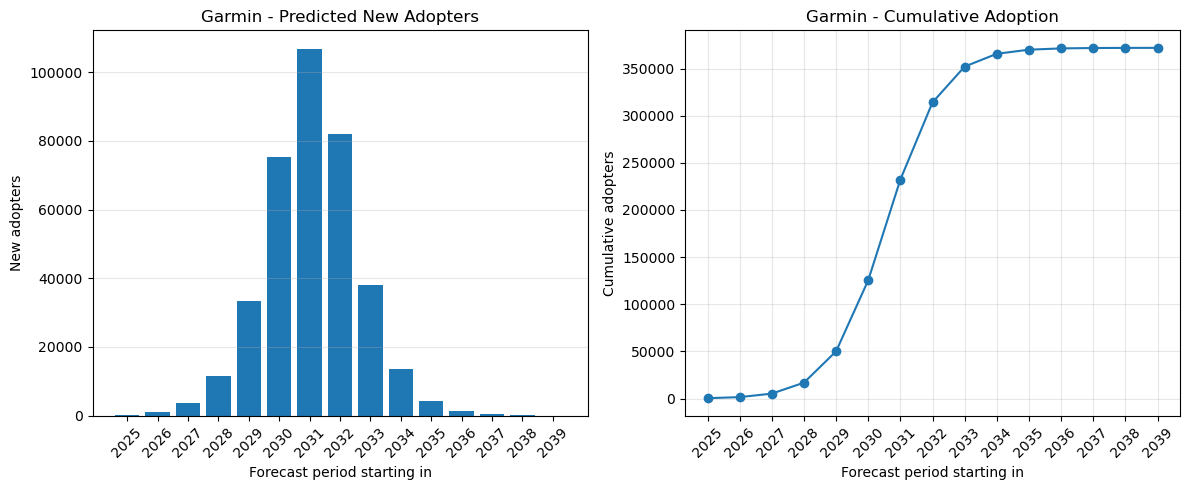

In [11]:
#Plotting Garmin's predicted new and cumulative adopters
plt.figure(figsize=(12, 5))
#New adopters in each year
plt.subplot(1, 2, 1)
plt.bar(garmin_forecast["Year"], garmin_forecast["New adopters"])
plt.title("Garmin - Predicted New Adopters")
plt.xlabel("Forecast period starting in")
plt.ylabel("New adopters")
plt.xticks(garmin_forecast["Year"], rotation=45)
plt.grid(axis="y", alpha=0.3)

#Total adopters over time
plt.subplot(1, 2, 2)
plt.plot(garmin_forecast["Year"],
         garmin_forecast["Cumulative adopters"],
         marker="o")
plt.title("Garmin - Cumulative Adoption")
plt.xlabel("Forecast period starting in")
plt.ylabel("Cumulative adopters")
plt.xticks(garmin_forecast["Year"], rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("img/garmin_adoption_forecast.png",
            dpi=200, bbox_inches="tight")
plt.show()

Garmin Market Scenario Comparison


,Scenario,Market potential,Peak period,Peak new adopters,Cumulative by 2039
0,Low,186000,2031,53408,185991
1,Base,372000,2031,106817,371983
2,High,930000,2031,267042,929957


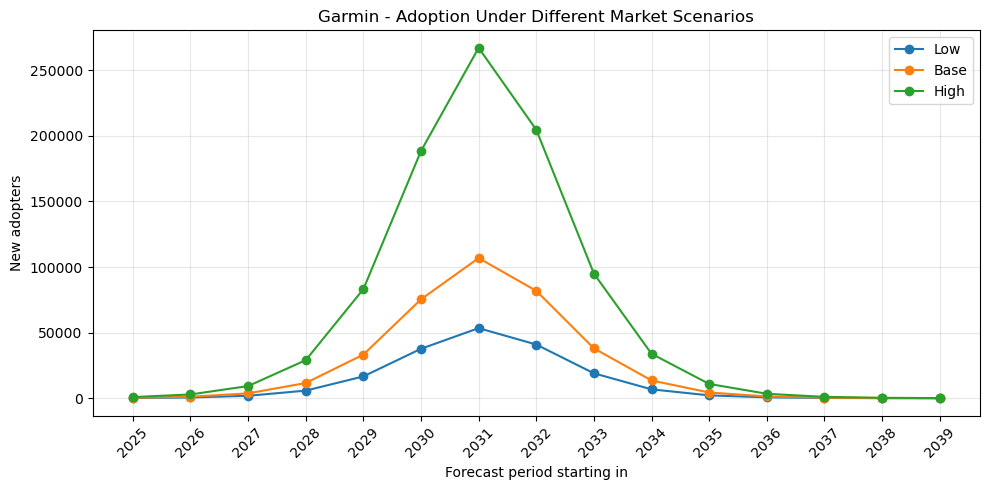

In [12]:
#Comparing the three Garmin market scenarios
scenario_results = []
scenario_forecasts = []

plt.figure(figsize=(10, 5))

for _, row in market_scenarios.iterrows():
    name = row["Scenario"]
    M_scenario = int(row["Market potential"])

    #Predicting new and cumulative adopters
    new = M_scenario * (
        bass_F(t_forecast, p, q) - bass_F(t_forecast - 1, p, q)
    )
    cumulative = M_scenario * bass_F(t_forecast, p, q)

#Finding the peak adoption period
    peak_index = np.argmax(new)

    scenario_results.append({
        "Scenario": name,
        "Market potential": M_scenario,
        "Peak period": forecast_years[peak_index],
        "Peak new adopters": round(new[peak_index]),
        "Cumulative by 2039": round(cumulative[-1])
    })

    for i in range(len(forecast_years)):
        scenario_forecasts.append({
            "Scenario": name,
            "Year": forecast_years[i],
            "New adopters": round(new[i]),
            "Cumulative adopters": round(cumulative[i])
        })

    plt.plot(forecast_years, new, marker="o", label=name)

#Summary table
scenario_summary = pd.DataFrame(scenario_results)

print("Garmin Market Scenario Comparison")
display(scenario_summary)

#Plotting the three scenarios
plt.title("Garmin - Adoption Under Different Market Scenarios")
plt.xlabel("Forecast period starting in")
plt.ylabel("New adopters")
plt.xticks(forecast_years, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

scenario_summary.to_csv("data/garmin_scenario_summary.csv", index=False)
pd.DataFrame(scenario_forecasts).to_csv(
    "data/garmin_scenario_forecasts.csv", index=False
)

plt.savefig("img/garmin_scenario_comparison.png",
            dpi=200, bbox_inches="tight")
plt.show()

## 7)Garmin Index Sleep Monitor Diffusion Forecast

To predict the adoption of Garmin Index Sleep Monitor, I used the p and q values estimated from Fitbit's historical data. For the market potential, I used my base scenario of 372000 devices. Since I am predicting adoption for each year, I calculated the number of new adopters using the difference between cumulative adoption at the end and beginning of each period:
$$
\text{New adopters}_t=M[F(t)-F(t-1)]
$$

The results show that adoption starts slowly and then increases quickly. In the first forecast period, starting in 2025, the model predicts around 354 new adopters and the number increases over the following periods and reaches its highest point in the period starting in 2031, with approximately 106817 new adopters. After that, the number of new adopters gradually decreases as the market approaches its assumed potential.

The cumulative adoption graph has an S-shape. At first, only a small part of the market adopts the product. Later, adoption becomes faster, and finally it slows down as fewer potential customers remain. By the end of the 15th period, the model predicts approximately 371983 cumulative adopters, which is close to the assumed market potential of 372000.

I also compared three market scenarios to see how the results change. In the low scenario, the model predicts approximately 53408 new adopters in the peak period. In the base scenario, this increases to 106817, while in the high scenario it reaches 267042. All three scenarios have the same peak period because I kept p and q unchanged and only changed M.

However, these numbers cannot be considered exact predictions of Garmin's future sales. The model uses Fitbit's historical adoption pattern, but the Garmin Index Sleep Monitor is a more specialized product. Fitbit's imitation coefficient is also quite high, which makes the predicted adoption grow quickly. My three scenarios only show uncertainty about market size, not uncertainty about the innovation and imitation coefficients.

Overall,the Bass Model shows the possible pattern of slow initial growth, faster adoption, and eventual saturation. However, actual sales could be very different because of product price, competition, customer preferences, and the size of the sleep-tracking market.

## 8)Conclusion
In this homework, I used the Bass Model to predict how the Garmin Index Sleep Monitor might be adopted over time. Since the product was introduced in 2025, I used historical Fitbit sales data to estimate the innovation and imitation coefficients.
The results suggest that imitation has a stronger influence than innovation in the fitted Fitbit model. Using these parameters and my estimated Garmin market potential of 372000 devices, the model predicts that adoption will reach its highest level in the seventh forecast period, with approximately 106817 new adopters.
However, I think the most important limitation is that the two products are not exactly the same. Fitbit is a general fitness tracker, while Garmin Index Sleep Monitor focuses mainly on sleep. Also, the Bass Model fitted Fitbit's early sales much better than its later sales which means that Garmin's actual adoption could be different from the predictions.

The forecast covers 15 years, starting from the product's launch in 2025. Each forecast period represents 12 months, and the year labels indicate when each period begins rather than exact calendar-year sales.

## References

1. Alderton, M. (2025, October 9). *Garmin Index Sleep Monitor*. TIME. https://time.com/collections/best-inventions-2025/7318552/garmin-index-sleep-monitor/

2. Bass, F. M. (1969). A new product growth for model consumer durables. *Management Science, 15*(5), 215–227. https://doi.org/10.1287/mnsc.15.5.215

3. Fitbit, Inc. (2015). *Registration statement (Form S-1).* U.S. Securities and Exchange Commission. https://www.sec.gov/Archives/edgar/data/1447599/000119312515176980/d875679ds1.htm

4. Fitbit, Inc. (2020). *Annual report for fiscal year 2019 (Form 10-K).* U.S. Securities and Exchange Commission. https://www.sec.gov/Archives/edgar/data/1447599/000144759920000016/fit-20191231.htm

5. Garmin Ltd. (2025). *2024 annual report (Form 10-K).* https://www8.garmin.com/aboutGarmin/invRelations/reports/2024_Annual_Report.pdf

6. Garmin. (2025, June 18). *Rest easy with the Index Sleep Monitor smart sleep band from Garmin.* https://www.garmin.com/en-US/newsroom/press-release/wearables-health/rest-easy-with-the-index-sleep-monitor-smart-sleep-band-from-garmin/

7. Garmin Singapore. (2025). *Rest easy with the Index Sleep Monitor smart sleep band from Garmin.* https://www.garmin.com.sg/news/press-release/news-2025-jul-index-sleep-monitor/

8. Hovhannisyan, K. (2026). *Bass model for innovation diffusion* [Course lecture slides]. DS 223 Marketing Analytics, American University of Armenia.